In [3]:

# ============================================================
# PRACTICAL 1: LAYER NORMALIZATION
# ============================================================

# 1. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler





In [4]:
# 2. Create Dataset
X, y = make_moons(
    n_samples=3000,
    noise=0.25,
    random_state=42
)

# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# 5. Build Model
def build_model(use_layer_norm=False):

    layers = [
        tf.keras.layers.Input(shape=(2,)),
        tf.keras.layers.Dense(
            64,
            use_bias=not use_layer_norm
        )
    ]

    # Apply Layer Normalization
    if use_layer_norm:
        layers.append(
            tf.keras.layers.LayerNormalization(axis=-1)
        )

    layers.extend([
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model = tf.keras.Sequential(layers)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# 6. Train Models and Compare Results
results = {}
histories = {}

for use_norm in [False, True]:

    model_name = (
        "With LayerNorm"
        if use_norm
        else "Without LayerNorm"
    )

    print("\nTraining:", model_name)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model(use_layer_norm=use_norm)

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=40,
        batch_size=32,
        verbose=1
    )

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    histories[model_name] = history.history

    results[model_name] = {
        "Test Loss": test_loss,
        "Test Accuracy": test_accuracy
    }

    print("Test Loss:", round(test_loss, 4))
    print("Test Accuracy:", round(test_accuracy, 4))



Training data: (2400, 2)
Testing data: (600, 2)

Training: Without LayerNorm
Epoch 1/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8198 - loss: 0.4890 - val_accuracy: 0.8396 - val_loss: 0.3728
Epoch 2/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8583 - loss: 0.3193 - val_accuracy: 0.8500 - val_loss: 0.3310
Epoch 3/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8594 - loss: 0.3033 - val_accuracy: 0.8562 - val_loss: 0.3148
Epoch 4/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8672 - loss: 0.2893 - val_accuracy: 0.8667 - val_loss: 0.2960
Epoch 5/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8766 - loss: 0.2731 - val_accuracy: 0.8771 - val_loss: 0.2742
Epoch 6/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8911 - loss: 0.2546 - val_accuracy: 0.8833 - val_loss: 0.2502
Epoch 7/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9047 - loss: 0.2354 - val_accuracy: 0.8938 - val_loss: 0.2265
Epoch 8/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 


Final Model Comparison:
                   Test Loss  Test Accuracy
Without LayerNorm   0.145005       0.946667
With LayerNorm      0.308860       0.875000


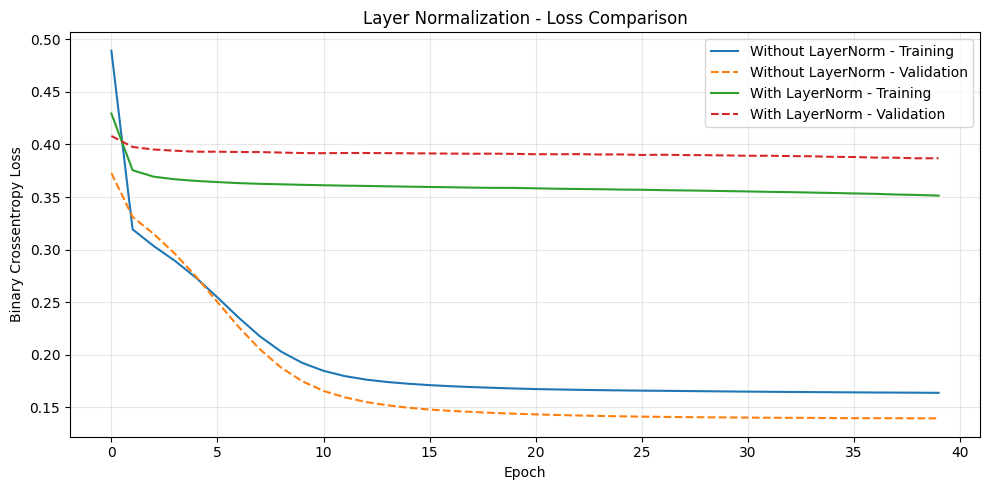

In [5]:
# 7. Display Comparison
results_df = pd.DataFrame(results).T
print("\nFinal Model Comparison:")
print(results_df)

# 8. Plot Training and Validation Loss
plt.figure(figsize=(10, 5))

for name, history in histories.items():
    plt.plot(
        history["loss"],
        label=f"{name} - Training"
    )

    plt.plot(
        history["val_loss"],
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.title("Layer Normalization - Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

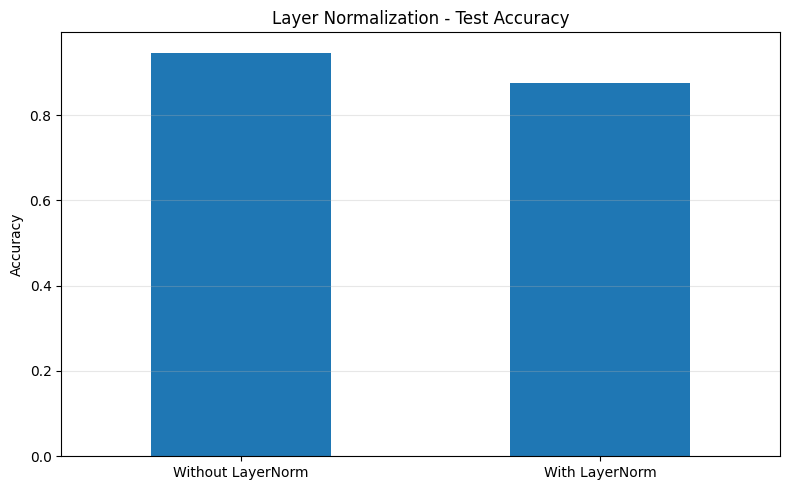

In [6]:



# 9. Plot Test Accuracy Comparison
results_df["Test Accuracy"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Layer Normalization - Test Accuracy"
)

plt.ylabel("Accuracy")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()